# CVMatch IA — Bloc 1 : création, gestion et analyse des données

**Question posée :** qu'est-ce qui fait qu'un CV correspond à une offre d'emploi ?
Les réponses servent directement à l'application : elles justifient la façon dont on calcule
le score de compatibilité (bloc 2, deep matching) et ce qu'on montre au recruteur.

Plan, dans l'ordre de la grille d'évaluation :
1. **Collecter** les données et expliquer leur origine
2. **Nettoyer et préparer** : valeurs manquantes, doublons, erreurs, formats, incohérences
3. **Structurer et stocker** dans une base SQL (SQLite)
4. **Analyser** : statistiques, regroupements, comparaisons
5. **Visualiser et interpréter** : graphiques et conclusions

> Pour relancer : `modele\.venv\Scripts\python.exe -m jupyter nbconvert --execute --to notebook --inplace analyse\analyse_donnees.ipynb`

In [1]:
import re
import sqlite3
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DONNEES = Path('..') / 'modele' / 'donnees'
GRAPHIQUES = Path('graphiques')
GRAPHIQUES.mkdir(exist_ok=True)
BASE = Path('cvmatch_donnees.db')

pd.set_option('display.max_colwidth', 80)

# Style commun des graphiques : fond clair, axes discrets, une couleur par étiquette (toujours la même)
BLEU, ORANGE, VERT = '#2a78d6', '#eb6834', '#1baf7a'
COULEURS_ETIQUETTES = {'No Fit': ORANGE, 'Potential Fit': BLEU, 'Good Fit': VERT}
ETIQUETTES = ['No Fit', 'Potential Fit', 'Good Fit']
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'text.color': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e8e7e2',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'figure.dpi': 110,
})


def enregistrer(fig, nom):
    fig.tight_layout()
    fig.savefig(GRAPHIQUES / f'{nom}.png', dpi=130)
    plt.show()

## 1. Collecter les données

**Source :** le jeu public [`cnamuangtoun/resume-job-description-fit`](https://huggingface.co/datasets/cnamuangtoun/resume-job-description-fit)
sur Hugging Face, récupéré avec `modele/telecharger_donnees.py`.

**Pourquoi ce jeu :** pour apprendre à juger si un CV correspond à une offre, il faut des exemples **déjà jugés**.
Notre application n'a encore que quelques comptes de test : pas assez. Ce jeu contient des paires
(CV, offre d'emploi) étiquetées par des humains en trois niveaux :

| Étiquette | Sens |
|---|---|
| `No Fit` | le CV ne correspond pas à l'offre |
| `Potential Fit` | correspondance partielle |
| `Good Fit` | bonne correspondance |

**Limite à garder en tête :** les textes sont en **anglais** (marché américain) alors que l'application est en français.
C'est pour ça que le modèle du bloc 2 utilise des embeddings **multilingues**.

Le jeu est livré en deux fichiers déjà séparés : `train.csv` (entraînement) et `test.csv` (évaluation).

In [2]:
brut = pd.concat(
    [pd.read_csv(DONNEES / 'train.csv').assign(source='train'),
     pd.read_csv(DONNEES / 'test.csv').assign(source='test')],
    ignore_index=True,
).rename(columns={'resume_text': 'cv', 'job_description_text': 'offre', 'label': 'etiquette'})

print(f'{len(brut)} paires CV ↔ offre, {brut.shape[1]} colonnes')
brut.head(3)

8000 paires CV ↔ offre, 4 colonnes


,cv,offre,etiquette,source
0,SummaryHighly motivated Sales Associate with extensive customer service and ...,Net2Source Inc. is an award-winning total workforce solutions company recogn...,No Fit,train
1,Professional SummaryCurrently working with Caterpillar as an contract employ...,At Salas OBrien we tell our clients that were engineered for impact. This pa...,No Fit,train
2,"SummaryI started my construction career in June of 2017 in Jacksonville, Flo...",Schweitzer Engineering Laboratories (SEL) Infrastructure Defense Division se...,No Fit,train


In [3]:
brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   cv         8000 non-null   str  
 1   offre      8000 non-null   str  
 2   etiquette  8000 non-null   str  
 3   source     8000 non-null   str  
dtypes: str(4)
memory usage: 250.1 KB


## 2. Nettoyer et préparer les données

On vérifie chaque type de problème de la grille, on le **mesure**, puis on le corrige.
On garde une trace de chaque étape dans `journal`.

In [4]:
d = brut.copy()
journal = [('Données brutes', len(d))]

# --- 2.1 Valeurs manquantes et textes vides
d['cv'] = d['cv'].astype(str).str.strip()
d['offre'] = d['offre'].astype(str).str.strip()
manquants = brut[['cv', 'offre', 'etiquette']].isna().sum()
vides = ((d['cv'] == '') | (d['offre'] == '')).sum()
print('Valeurs manquantes par colonne :', manquants.to_dict())
print('Textes vides ou faits seulement d’espaces :', vides)
d = d[(d['cv'] != '') & (d['offre'] != '')]

# --- 2.2 Étiquettes valides uniquement
print('Étiquettes présentes :', sorted(d['etiquette'].unique()))
d = d[d['etiquette'].isin(ETIQUETTES)]
journal.append(('Sans manquants ni étiquettes invalides', len(d)))

Valeurs manquantes par colonne : {'cv': 0, 'offre': 0, 'etiquette': 0}
Textes vides ou faits seulement d’espaces : 0
Étiquettes présentes : ['Good Fit', 'No Fit', 'Potential Fit']


### 2.2 Erreurs de format dans les textes

Les CV ont été extraits de PDF : les titres de section sont **collés** au texte
(`SummaryHighly motivated…`), des phrases sont recollées (`record.Proven`) et on trouve
des espaces insécables (`\xa0`). On les mesure avant de corriger.

In [5]:
TITRES = ('Professional Summary|Executive Summary|Career Overview|Professional Background|Professional Profile|'
          'Summary|Profile|Objective|Highlights|Skills|Experience|Work History|Education|Accomplishments|Certifications')
RE_TITRE_COLLE = re.compile(rf'^({TITRES})(?=[A-Z0-9➢•\-])', re.M)
RE_PHRASE_COLLEE = re.compile(r'([a-z])\.([A-Z])')


def nettoyer_texte(texte):
    texte = unicodedata.normalize('NFKC', texte)          # espaces insécables, ligatures… → forme standard
    texte = RE_TITRE_COLLE.sub(r'\1\n', texte)            # « SummaryHighly » → « Summary » + retour à la ligne
    texte = RE_PHRASE_COLLEE.sub(r'\1. \2', texte)         # « record.Proven » → « record. Proven »
    texte = re.sub(r'[ \t]+', ' ', texte)                  # espaces multiples
    texte = re.sub(r' *\n[ \n]*', '\n', texte)            # lignes vides en trop
    return texte.strip()


def compter(serie):
    return pd.Series({
        'titres collés': serie.map(lambda t: bool(RE_TITRE_COLLE.search(t))).sum(),
        'phrases collées': serie.map(lambda t: bool(RE_PHRASE_COLLEE.search(t))).sum(),
        'espaces insécables': serie.str.contains('\xa0', regex=False).sum(),
    })


avant = pd.DataFrame({'CV': compter(d['cv']), 'offres': compter(d['offre'])})
d['cv'] = d['cv'].map(nettoyer_texte)
d['offre'] = d['offre'].map(nettoyer_texte)
apres = pd.DataFrame({'CV': compter(d['cv']), 'offres': compter(d['offre'])})
pd.concat({'avant': avant, 'après': apres}, axis=1)

avant        après       
                      CV offres    CV offres
titres collés       7927    108     4      9
phrases collées     7676   4592     0      0
espaces insécables  1112     20     0      0

In [6]:
print('Exemple de début de CV après nettoyage :\n')
print(d['cv'].iloc[0][:300])

Exemple de début de CV après nettoyage :

Summary
Highly motivated Sales Associate with extensive customer service and sales experience. Outgoing sales professional with track record of driving increased sales, improving buying experience and elevating company profile with target market.
Highlights
-Soft Skills: Public Speaking, Public Rela


### 2.3 Doublons

Trois cas différents :
- la **même ligne** deux fois → on n'en garde qu'une ;
- la **même paire** CV + offre avec des **étiquettes différentes** : les annotateurs se contredisent,
  on ne sait pas laquelle croire → on retire ces paires ;
- le **même CV** à la fois dans `train` et dans `test` : ce n'est pas une erreur de saisie,
  mais c'est une **fuite** : le modèle est évalué sur des CV qu'il a déjà vus (voir 2.5).

In [7]:
n = len(d)
d = d.drop_duplicates(subset=['cv', 'offre', 'etiquette'])
print(f'Lignes en double supprimées : {n - len(d)}')

nb_etiquettes = d.groupby(['cv', 'offre'])['etiquette'].transform('nunique')
contradictoires = d[nb_etiquettes > 1]
print(f'Paires contradictoires : {contradictoires.groupby(["cv", "offre"]).ngroups} '
      f'({len(contradictoires)} lignes retirées)')
d = d[nb_etiquettes == 1]
journal.append(('Sans doublons ni contradictions', len(d)))

cv_train, cv_test = set(d.loc[d.source == 'train', 'cv']), set(d.loc[d.source == 'test', 'cv'])
print(f'CV présents à la fois dans train et test : {len(cv_train & cv_test)} sur {d.cv.nunique()} CV différents')

Lignes en double supprimées : 1


Paires contradictoires : 6 (12 lignes retirées)


CV présents à la fois dans train et test : 476 sur 643 CV différents


### 2.4 Données incohérentes et variables utiles

On extrait des **variables** qui serviront à l'analyse :
- **longueur** (en mots) du CV et de l'offre ;
- **années d'expérience** mentionnées (« 5 years… ») dans le CV et demandées dans l'offre ;
- **domaine** du CV et de l'offre (informatique, finance, santé…) par mots-clés ;
- **compétences** connues trouvées dans le texte, et la part des compétences de l'offre présentes dans le CV ;
- **recouvrement de mots-clés** : la part des mots de l'offre présents dans le CV (le calcul de `match.js`).

Valeurs incohérentes traitées :
- une offre trop courte pour être jugée (moins de 30 mots) → retirée ;
- un nombre d'années supérieur à 40 (ex. « 75 years » = âge de l'entreprise) → mis à vide (`NaN`), pas inventé.

In [8]:
d['mots_cv'] = d['cv'].str.split().str.len()
d['mots_offre'] = d['offre'].str.split().str.len()

trop_courtes = d[d['mots_offre'] < 30]
print(f'{trop_courtes.offre.nunique()} offres trop courtes ({len(trop_courtes)} paires retirées) :')
for texte in trop_courtes['offre'].unique():
    print(' -', texte[:120])
d = d[d['mots_offre'] >= 30].copy()
journal.append(('Sans offres trop courtes', len(d)))

RE_ANNEES = re.compile(r'(\d{1,2})\+?\s*(?:years|yrs)', re.I)


def annees(texte):
    valeurs = [int(v) for v in RE_ANNEES.findall(texte)]
    return max(valeurs) if valeurs else np.nan


d['annees_cv'] = d['cv'].map(annees)
d['annees_offre'] = d['offre'].map(annees)
for col in ('annees_cv', 'annees_offre'):
    aberrantes = (d[col] > 40).sum()
    d.loc[d[col] > 40, col] = np.nan
    print(f'{col} : {aberrantes} valeurs aberrantes (> 40 ans) mises à vide, '
          f'{d[col].isna().mean():.0%} des lignes sans information')

3 offres trop courtes (54 paires retirées) :
 - Experienced Business Analyst in Telecom PromosAnalyze promo & defect data and create analyses & summarize as specified. 
 - Title: PMLocation: Chicago, ILType: full-time (Hybrid)
Qualifications:Having knowledge on Structured Vs Unstructured dat
 - I own a small landscaping business that needs help with accountingtaxes.


annees_cv : 47 valeurs aberrantes (> 40 ans) mises à vide, 59% des lignes sans information
annees_offre : 187 valeurs aberrantes (> 40 ans) mises à vide, 26% des lignes sans information


In [9]:
DOMAINES = {
    'Informatique & data': ['software', 'developer', 'programming', 'python', 'java', 'sql', 'database', 'data analy',
                            'data scien', 'devops', 'cloud', 'web develop', 'network', 'it support', 'machine learning'],
    'Finance & comptabilité': ['accountant', 'accounting', 'finance', 'financial', 'audit', 'tax', 'bookkeep', 'payroll'],
    'Santé': ['medical', 'nurse', 'nursing', 'patient', 'clinical', 'healthcare', 'hospital', 'pharma'],
    'Commerce & vente': ['sales', 'retail', 'customer service', 'marketing', 'store', 'merchandis'],
    'RH & administration': ['human resources', 'recruit', 'administrative', 'office manager', 'clerk', 'receptionist'],
    'Ingénierie & industrie': ['mechanical', 'electrical', 'manufacturing', 'construction', 'maintenance', 'production'],
}


def domaine(texte):
    t = texte.lower()
    scores = {nom: sum(t.count(m) for m in mots) for nom, mots in DOMAINES.items()}
    meilleur = max(scores, key=scores.get)
    return meilleur if scores[meilleur] > 0 else 'Autre'


# Le CV : son début (titre + résumé) dit le métier. L'offre : tout le texte.
d['domaine_cv'] = d['cv'].str[:1000].map(domaine)
d['domaine_offre'] = d['offre'].map(domaine)
d['meme_domaine'] = d['domaine_cv'] == d['domaine_offre']
d['domaine_cv'].value_counts()

domaine_cv
Informatique & data       4968
Finance & comptabilité    1367
Commerce & vente           683
Ingénierie & industrie     426
Santé                      196
RH & administration        154
Autre                      139
Name: count, dtype: int64

In [10]:
COMPETENCES = ['python', 'java', 'javascript', 'sql', 'excel', 'aws', 'azure', 'docker', 'kubernetes', 'linux', 'git',
               'react', 'tableau', 'power bi', 'machine learning', 'salesforce', 'sap', 'quickbooks', 'agile', 'scrum',
               'c++', 'c#', '.net', 'html', 'css', 'project management', 'customer service', 'communication',
               'leadership', 'sales', 'marketing', 'accounting', 'budgeting', 'scheduling', 'data analysis',
               'microsoft office', 'networking', 'troubleshooting', 'negotiation', 'training']


def competences(texte):
    t = texte.lower()
    return {c for c in COMPETENCES if re.search(rf'(?<![a-z0-9]){re.escape(c)}(?![a-z0-9+#])', t)}


MOTS_VIDES = set('the and for with you our are will from this that have has your can all who in of to a an on as at or by be is'.split())


def mots(texte):
    texte = unicodedata.normalize('NFD', texte.lower())
    texte = ''.join(c for c in texte if unicodedata.category(c) != 'Mn')
    return {m for m in re.split(r'[^a-z0-9+#]+', texte) if len(m) > 1 and m not in MOTS_VIDES}


comp_cv = d['cv'].map(competences)
comp_offre = d['offre'].map(competences)
d['nb_competences_offre'] = comp_offre.str.len()
d['couverture_competences'] = [len(c & o) / len(o) if o else np.nan for c, o in zip(comp_cv, comp_offre)]
d['recouvrement_mots'] = [len(mots(c) & mots(o)) / max(len(mots(o)), 1) for c, o in zip(d['cv'], d['offre'])]
d['competences_offre'] = comp_offre.map(lambda s: ', '.join(sorted(s)))
d[['mots_cv', 'mots_offre', 'annees_cv', 'annees_offre', 'couverture_competences', 'recouvrement_mots']].describe().round(2)

,mots_cv,mots_offre,annees_cv,annees_offre,couverture_competences,recouvrement_mots
count,7933.00,7933.00,3279.00,5867.00,7505.00,7933.00
mean,730.11,386.36,7.65,7.31,0.33,0.19
std,397.98,251.27,4.77,3.93,0.31,0.08
min,89.00,32.00,1.00,1.00,0.00,0.00
25%,503.00,174.00,5.00,5.00,0.00,0.13
50%,645.00,328.00,7.00,7.00,0.29,0.17
75%,837.00,556.00,9.00,10.00,0.50,0.23
max,3267.00,1263.00,35.00,35.00,1.00,0.77


### 2.5 Nouveau découpage entraînement / test, sans fuite

Le découpage d'origine sépare bien les **offres**, mais met des **CV** en commun entre `train` et `test` :
le modèle est alors testé sur des CV qu'il a déjà vus, et ses résultats sont trop optimistes.

Dans l'application, le modèle note un **nouveau** CV face à une **nouvelle** offre. Le test doit faire pareil :
on met de côté 30 % des CV et 30 % des offres ; le test ne garde que les paires dont le CV **et** l'offre sont mis
de côté, l'entraînement celles dont ni l'un ni l'autre ne l'est. Les paires mélangées sont écartées.
Le test est petit : le bloc 2 (`modele/entrainer.py`) répète ce tirage 5 fois. Ci-dessous, un tirage pour illustrer.

In [11]:
d['id_cv'] = d['cv'].factorize()[0]
d['id_offre_tmp'] = d['offre'].factorize()[0]
hasard = np.random.default_rng(0)
cvs_test = hasard.choice(d['id_cv'].unique(), int(d['id_cv'].nunique() * 0.3), replace=False)
offres_test = hasard.choice(d['id_offre_tmp'].unique(), int(d['id_offre_tmp'].nunique() * 0.3), replace=False)
cv_test, offre_test = d['id_cv'].isin(cvs_test), d['id_offre_tmp'].isin(offres_test)
d['jeu'] = np.select([~cv_test & ~offre_test, cv_test & offre_test], ['train', 'test'], 'écarté')
d = d.drop(columns='id_offre_tmp')

for colonne in ('cv', 'offre'):
    communs = set(d.loc[d.jeu == 'train', colonne]) & set(d.loc[d.jeu == 'test', colonne])
    print(f'{colonne} communs train/test : {len(communs)}')
pd.concat([d['jeu'].value_counts().rename('paires'),
           pd.crosstab(d['jeu'], d['etiquette'], normalize='index').round(3)[ETIQUETTES]], axis=1)

cv communs train/test : 0
offre communs train/test : 0


,paires,No Fit,Potential Fit,Good Fit
jeu,,,,
train,3974,0.505,0.241,0.255
écarté,3290,0.501,0.248,0.251
test,669,0.471,0.293,0.236


In [12]:
journal_df = pd.DataFrame(journal, columns=['étape', 'lignes'])
journal_df['retirées'] = (-journal_df['lignes'].diff()).fillna(0).astype(int)
journal_df

,étape,lignes,retirées
0,Données brutes,8000,0
1,Sans manquants ni étiquettes invalides,8000,0
2,Sans doublons ni contradictions,7987,13
3,Sans offres trop courtes,7933,54


## 3. Structurer et stocker les données

Dans les fichiers d'origine, chaque ligne recopie le texte entier du CV et de l'offre :
un même CV est répété jusqu'à plusieurs dizaines de fois. On range les données dans une **base SQL**
normalisée, comme la base MySQL de l'application :

```
cvs (id, texte, mots, annees_experience, domaine)
offres (id, texte, mots, annees_demandees, domaine, competences)
paires (id, cv_id → cvs.id, offre_id → offres.id, etiquette, source, jeu, recouvrement_mots, couverture_competences)
```

On utilise **SQLite** (un fichier `cvmatch_donnees.db`, sans serveur) : même langage SQL que MySQL,
facile à partager avec le notebook.

In [13]:
d['id_offre'] = d['offre'].factorize()[0]
cvs = (d.drop_duplicates('id_cv')[['id_cv', 'cv', 'mots_cv', 'annees_cv', 'domaine_cv']]
       .set_axis(['id', 'texte', 'mots', 'annees_experience', 'domaine'], axis=1))
offres = (d.drop_duplicates('id_offre')[['id_offre', 'offre', 'mots_offre', 'annees_offre', 'domaine_offre', 'competences_offre']]
          .set_axis(['id', 'texte', 'mots', 'annees_demandees', 'domaine', 'competences'], axis=1))
paires = d[['id_cv', 'id_offre', 'etiquette', 'source', 'jeu', 'recouvrement_mots', 'couverture_competences']] \
    .rename(columns={'id_cv': 'cv_id', 'id_offre': 'offre_id'}).reset_index(drop=True)
paires.insert(0, 'id', paires.index)

BASE.unlink(missing_ok=True)
with sqlite3.connect(BASE) as con:
    con.executescript('''
        CREATE TABLE cvs (id INTEGER PRIMARY KEY, texte TEXT NOT NULL, mots INTEGER,
                          annees_experience REAL, domaine TEXT);
        CREATE TABLE offres (id INTEGER PRIMARY KEY, texte TEXT NOT NULL, mots INTEGER,
                             annees_demandees REAL, domaine TEXT, competences TEXT);
        CREATE TABLE paires (id INTEGER PRIMARY KEY, cv_id INTEGER NOT NULL REFERENCES cvs(id),
                             offre_id INTEGER NOT NULL REFERENCES offres(id),
                             etiquette TEXT NOT NULL CHECK (etiquette IN ('No Fit', 'Potential Fit', 'Good Fit')),
                             source TEXT, jeu TEXT, recouvrement_mots REAL, couverture_competences REAL);
    ''')
    cvs.to_sql('cvs', con, if_exists='append', index=False)
    offres.to_sql('offres', con, if_exists='append', index=False)
    paires.to_sql('paires', con, if_exists='append', index=False)

taille_csv = sum((DONNEES / f).stat().st_size for f in ('train.csv', 'test.csv')) / 1e6
print(f'{len(cvs)} CV, {len(offres)} offres, {len(paires)} paires')
print(f'Taille : {taille_csv:.0f} Mo en CSV → {BASE.stat().st_size / 1e6:.0f} Mo en base (textes stockés une seule fois)')

643 CV, 348 offres, 7933 paires
Taille : 69 Mo en CSV → 6 Mo en base (textes stockés une seule fois)


In [14]:
def sql(requete):
    with sqlite3.connect(BASE) as con:
        return pd.read_sql(requete, con)


# Vérification : la base se lit avec de simples requêtes SQL (jointure + regroupement)
sql('''
    SELECT c.domaine AS domaine_du_cv,
           COUNT(*) AS paires,
           ROUND(100.0 * SUM(p.etiquette = 'Good Fit') / COUNT(*), 1) AS pct_good_fit
    FROM paires p JOIN cvs c ON c.id = p.cv_id
    GROUP BY c.domaine
    ORDER BY paires DESC
''')

,domaine_du_cv,paires,pct_good_fit
0,Informatique & data,4968,26.7
1,Finance & comptabilité,1367,26.2
2,Commerce & vente,683,20.5
3,Ingénierie & industrie,426,12.2
4,Santé,196,23.5
5,RH & administration,154,29.2
6,Autre,139,21.6


## 4 & 5. Analyser, visualiser et interpréter

Chaque graphique est enregistré dans `analyse/graphiques/` pour la présentation.

### 4.1 Répartition des étiquettes

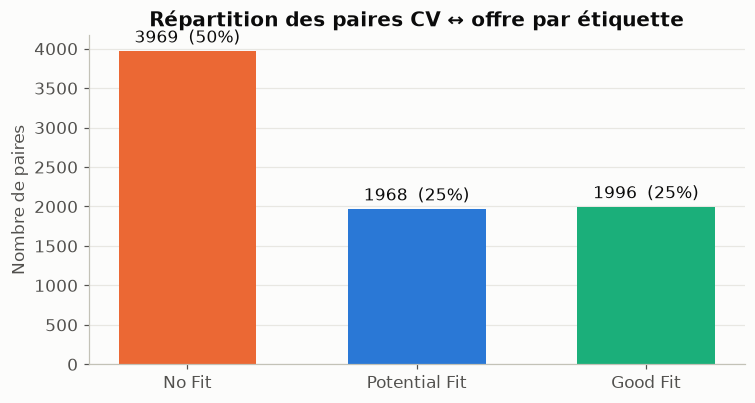

In [15]:
repartition = d['etiquette'].value_counts().reindex(ETIQUETTES)
fig, ax = plt.subplots(figsize=(7, 3.8))
barres = ax.bar(ETIQUETTES, repartition, color=[COULEURS_ETIQUETTES[e] for e in ETIQUETTES], width=0.6)
ax.bar_label(barres, labels=[f'{v}  ({v / repartition.sum():.0%})' for v in repartition], padding=3)
ax.set_title('Répartition des paires CV ↔ offre par étiquette')
ax.set_ylabel('Nombre de paires')
ax.grid(axis='x', visible=False)
enregistrer(fig, '1_etiquettes')

**Interprétation :** les classes sont **déséquilibrées** : la moitié des paires sont des `No Fit`.
Un modèle qui répondrait toujours « No Fit » aurait déjà ~50 % de bonnes réponses : c'est pour ça qu'on
juge le modèle avec le **F1 macro** (moyenne équitable des 3 classes) plutôt qu'avec l'exactitude seule.

### 4.2 Longueur des textes

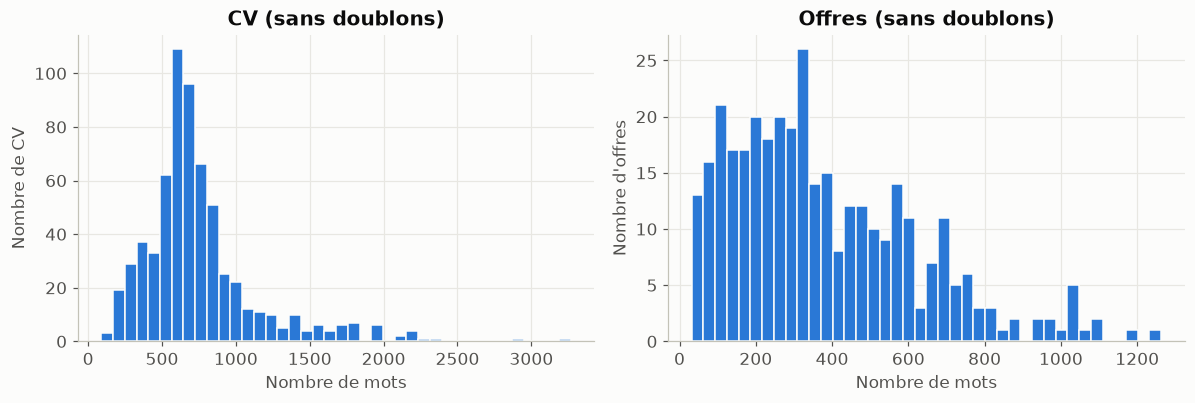

 texte  mots_moyens  min  max
    CV        751.0   89 3267
Offres        379.0   32 1263

               mots CV (médiane)  mots offre (médiane)
etiquette                                             
No Fit                     645.0                 318.0
Potential Fit              643.0                 313.5
Good Fit                   649.5                 359.0


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.hist(cvs['mots'], bins=40, color=BLEU, edgecolor='#fcfcfb', linewidth=1)
ax1.set_title('CV (sans doublons)')
ax1.set_xlabel('Nombre de mots')
ax1.set_ylabel('Nombre de CV')
ax2.hist(offres['mots'], bins=40, color=BLEU, edgecolor='#fcfcfb', linewidth=1)
ax2.set_title('Offres (sans doublons)')
ax2.set_xlabel('Nombre de mots')
ax2.set_ylabel("Nombre d'offres")
enregistrer(fig, '2_longueurs')

print(sql('''SELECT 'CV' AS texte, ROUND(AVG(mots)) AS mots_moyens, MIN(mots) AS min, MAX(mots) AS max FROM cvs
             UNION ALL SELECT 'Offres', ROUND(AVG(mots)), MIN(mots), MAX(mots) FROM offres''').to_string(index=False))
print()
print(d.groupby('etiquette')[['mots_cv', 'mots_offre']].median().reindex(ETIQUETTES).rename(
    columns={'mots_cv': 'mots CV (médiane)', 'mots_offre': 'mots offre (médiane)'}))

**Interprétation :** un CV fait en moyenne **plusieurs pages** (bien plus que les 512 « tokens », ~ une page,
que lit le modèle d'embeddings). C'est pour ça que le bloc 2 a comparé « début du CV » et « CV entier ».
La longueur ne change presque pas selon l'étiquette : un CV long n'est **pas** un meilleur CV.

### 4.3 Les mots-clés suffisent-ils ? (méthode actuelle de `match.js`)

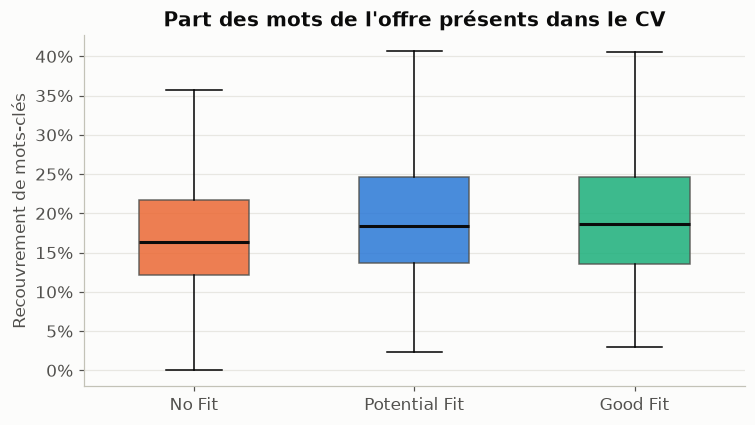

               moyenne %  médiane %
etiquette                          
No Fit              17.9       16.3
Potential Fit       19.7       18.4
Good Fit            19.6       18.7


In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
donnees_box = [d.loc[d.etiquette == e, 'recouvrement_mots'] for e in ETIQUETTES]
boites = ax.boxplot(donnees_box, tick_labels=ETIQUETTES, patch_artist=True, widths=0.5, showfliers=False,
                    medianprops={'color': '#0b0b0b', 'linewidth': 2})
for boite, e in zip(boites['boxes'], ETIQUETTES):
    boite.set(facecolor=COULEURS_ETIQUETTES[e], alpha=0.85, edgecolor='#52514e')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title("Part des mots de l'offre présents dans le CV")
ax.set_ylabel('Recouvrement de mots-clés')
ax.grid(axis='x', visible=False)
enregistrer(fig, '3_mots_cles')

moyennes = d.groupby('etiquette')['recouvrement_mots'].agg(['mean', 'median']).reindex(ETIQUETTES)
print((moyennes * 100).round(1).rename(columns={'mean': 'moyenne %', 'median': 'médiane %'}))

**Interprétation :** le recouvrement augmente un peu de `No Fit` à `Good Fit`, mais les boîtes se
**chevauchent presque entièrement** : avec les mots-clés seuls, on ne sait pas séparer un bon CV d'un mauvais.
**Décision :** c'est la justification du bloc 2 : remplacer le calcul par mots-clés par un modèle qui
comprend le **sens** des textes (embeddings), en gardant `match.js` en secours.

### 4.4 Le domaine du CV et celui de l'offre

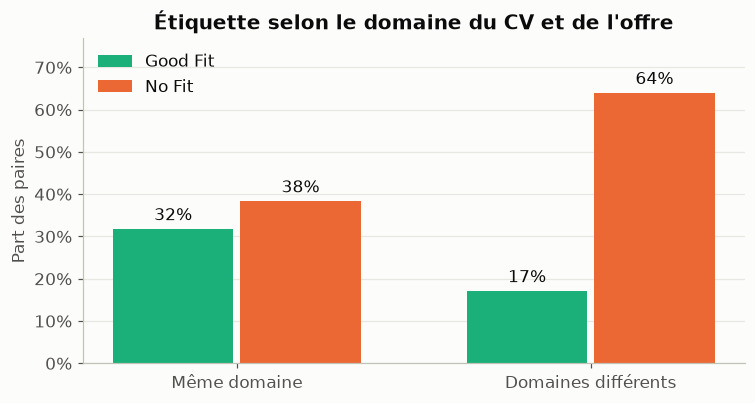

meme_domaine
même domaine           0.546
domaines différents    0.454
Name: proportion, dtype: float64


In [18]:
taux = (d.assign(good=d.etiquette == 'Good Fit', no=d.etiquette == 'No Fit')
        .groupby('meme_domaine')[['good', 'no']].mean()
        .rename(index={True: 'Même domaine', False: 'Domaines différents'})
        .loc[['Même domaine', 'Domaines différents']])

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(taux))
b1 = ax.bar(x - 0.18, taux['good'], 0.34, color=VERT, label='Good Fit')
b2 = ax.bar(x + 0.18, taux['no'], 0.34, color=ORANGE, label='No Fit')
for b in (b1, b2):
    ax.bar_label(b, labels=[f'{v:.0%}' for v in b.datavalues], padding=3)
ax.set_xticks(x, taux.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_ylim(0, max(taux.max()) * 1.2)
ax.set_title("Étiquette selon le domaine du CV et de l'offre")
ax.set_ylabel('Part des paires')
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
enregistrer(fig, '4_domaines')

print(d['meme_domaine'].value_counts(normalize=True).rename({True: 'même domaine', False: 'domaines différents'}).round(3))

**Interprétation :** quand le CV et l'offre sont du **même domaine**, la part de `Good Fit` est nettement plus
élevée. Le domaine (le métier) est donc un signal fort, ce qui confirme le choix de l'application de
demander le **métier** au candidat et à l'offre, et de le peser dans le score.

### 4.5 Les compétences les plus demandées

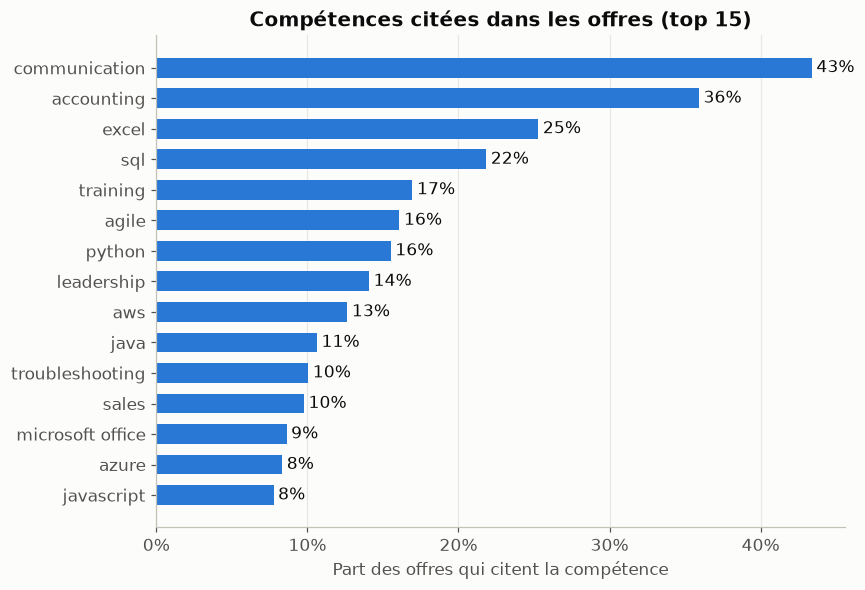

In [19]:
top = (offres['competences'].str.split(', ').explode().loc[lambda s: s != '']
       .value_counts().head(15).sort_values())
fig, ax = plt.subplots(figsize=(8, 5.5))
barres = ax.barh(top.index, top.values / len(offres), color=BLEU, height=0.65)
ax.bar_label(barres, labels=[f'{v:.0%}' for v in barres.datavalues], padding=3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Compétences citées dans les offres (top 15)')
ax.set_xlabel("Part des offres qui citent la compétence")
ax.grid(axis='y', visible=False)
enregistrer(fig, '5_competences')

**Interprétation :** « communication » est citée dans près d'une offre sur deux : elle ne permet presque pas
de distinguer les offres entre elles. Juste derrière viennent des compétences **techniques**
(comptabilité, Excel, SQL, Python…), à l'image des domaines les plus présents dans le jeu
(informatique et finance). Ce sont elles qui différencient vraiment les offres.

### 4.6 Couverture des compétences et écart d'expérience

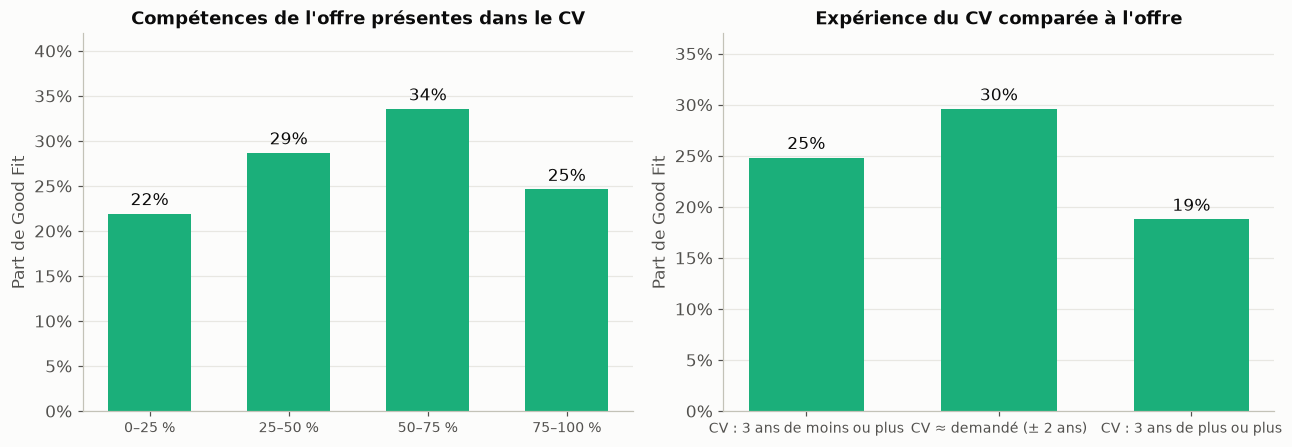

Couverture des compétences :
                    paires   taux  competences_dans_offre
tranche_couverture                                       
0–25 %                3637  0.219                     4.0
25–50 %               2313  0.287                     4.0
50–75 %                799  0.335                     4.0
75–100 %               756  0.246                     2.0

Écart d'expérience (paires où les deux sont connus) :
                             paires   taux
tranche_experience                        
CV : 3 ans de moins ou plus     681  0.248
CV ≈ demandé (± 2 ans)         1109  0.296
CV : 3 ans de plus ou plus      666  0.188


In [20]:
def pct_par_groupe(groupes, etiquette='Good Fit'):
    return (d.assign(cible=d.etiquette == etiquette)
            .groupby(groupes, observed=True)
            .agg(paires=('cible', 'size'), taux=('cible', 'mean')))


d['tranche_couverture'] = pd.cut(d['couverture_competences'], [-0.01, 0.25, 0.5, 0.75, 1],
                                 labels=['0–25 %', '25–50 %', '50–75 %', '75–100 %'])
ecart = d['annees_cv'] - d['annees_offre']
d['tranche_experience'] = pd.cut(ecart, [-100, -3, 2, 100],
                                 labels=['CV : 3 ans de moins ou plus', 'CV ≈ demandé (± 2 ans)', 'CV : 3 ans de plus ou plus'])

couverture = pct_par_groupe('tranche_couverture')
experience = pct_par_groupe('tranche_experience')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, tableau, titre in ((ax1, couverture, "Compétences de l'offre présentes dans le CV"),
                           (ax2, experience, "Expérience du CV comparée à l'offre")):
    barres = ax.bar(tableau.index.astype(str), tableau['taux'], color=VERT, width=0.6)
    ax.bar_label(barres, labels=[f'{v:.0%}' for v in tableau['taux']], padding=3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_ylim(0, tableau['taux'].max() * 1.25)
    ax.set_title(titre, fontsize=12)
    ax.set_ylabel('Part de Good Fit')
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelsize=9)
enregistrer(fig, '6_competences_experience')

print('Couverture des compétences :')
print(couverture.assign(competences_dans_offre=d.groupby('tranche_couverture', observed=True)['nb_competences_offre'].median()).round(3))
print()
print("Écart d'expérience (paires où les deux sont connus) :"); print(experience.round(3))

**Interprétation :**
- **Compétences :** plus le CV couvre de compétences de l'offre, plus la part de `Good Fit` monte
  (22 % → 34 %)… sauf la dernière tranche. Ces offres-là ne citent en général que **2** compétences connues
  (colonne `competences_dans_offre`) : les couvrir toutes est facile et ne prouve pas grand-chose.
  Compter les compétences ne suffit pas, il faut aussi tenir compte de **leur nombre et de leur importance**.
- **Expérience :** les meilleurs résultats sont quand l'expérience du CV **correspond** à celle demandée (± 2 ans).
  Un candidat **sur-qualifié** (3 ans de plus ou davantage) est moins souvent jugé `Good Fit`
  qu'un candidat qui en a un peu moins. Plus d'expérience n'est donc pas toujours mieux.
- Attention : l'expérience n'est connue des deux côtés que pour une partie des paires (voir 2.4).

## Conclusions

**Ce que les données nous apprennent :**

| Constat | Chiffre clé | Ce qu'on en fait dans CVMatch IA |
|---|---|---|
| Les mots-clés communs séparent mal les bonnes et mauvaises paires | recouvrement médian 16 % (No Fit) contre 19 % (Good Fit) | Bloc 2 : score calculé par un modèle entraîné sur le **sens** des textes ; `match.js` gardé en secours |
| Le domaine (métier) est le signal le plus fort | Good Fit : 32 % si même domaine, 17 % sinon | Le métier est obligatoire dans le profil candidat et dans l'offre |
| L'expérience doit **correspondre**, pas seulement être grande | Good Fit : 30 % si ± 2 ans, 19 % si sur-qualifié | Comparer les années du candidat à celles demandées, dans les deux sens |
| Classes déséquilibrées | 50 % de No Fit | Évaluer le modèle avec le **F1 macro**, pas seulement l'exactitude |
| Fuite entre entraînement et test d'origine | 476 CV communs | Bloc 2 réévalué sur des paires dont le CV **et** l'offre sont nouveaux (5 tirages) |

**Qualité des données :** 8 000 paires au départ, **7 933** après nettoyage (doublons, paires contradictoires,
offres trop courtes), textes corrigés (titres et phrases collés, espaces insécables), valeurs aberrantes
d'expérience mises à vide, et une base SQL **10 fois plus légère** que les CSV d'origine.

**Limites :**
- données **en anglais** et issues du marché américain : l'application vise un public francophone ;
- le domaine et les compétences sont repérés par **listes de mots-clés** : approximatif mais vérifiable ;
- les étiquettes viennent d'annotateurs humains et ne sont pas parfaites (6 paires contradictoires trouvées).